In [1]:
!pip install seaborn


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Import data

In [2]:
import pandas as pd

df = pd.read_csv("WELFake_Dataset.csv")

## Exploratory Data Analysis (EDA)  

In [3]:
# Dimension of the dataset
print(f"Number of records: {len(df)}")
print(f"(rows, columns): {df.shape}")

Number of records: 72134
(rows, columns): (72134, 4)


In [4]:
# Variables 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 72134 entries, 0 to 72133
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  72134 non-null  int64
 1   title       71576 non-null  str  
 2   text        72095 non-null  str  
 3   label       72134 non-null  int64
dtypes: int64(2), str(2)
memory usage: 2.2 MB


label
1    37106
0    35028
Name: count, dtype: int64
label
1    51.440375
0    48.559625
Name: proportion, dtype: float64


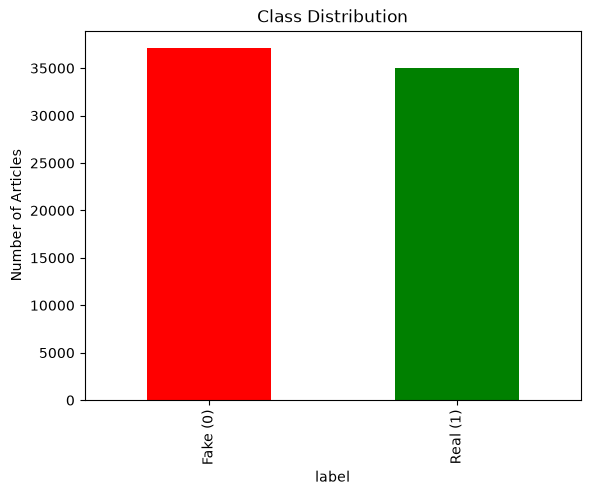

In [5]:
# Class distribution

print(df['label'].value_counts())
print(df['label'].value_counts(normalize=True) * 100)

# Graph of class distribution
import matplotlib.pyplot as plt

df['label'].value_counts().plot(kind='bar', color=['red', 'green'])
plt.xticks([0, 1], ['Fake (0)', 'Real (1)'])
plt.title('Class Distribution')
plt.ylabel('Number of Articles')
plt.show()

In [6]:
# text length (word count) for title and text, excluding missing values
df['title_length'] = df['title'].apply(lambda x: len(str(x).split()) if pd.notnull(x) else None)
df['text_length'] = df['text'].apply(lambda x: len(str(x).split()) if pd.notnull(x) else None)

print(df['title_length'].describe())
print(df['text_length'].describe())

# same stats split by class
print(df.groupby('label')[['title_length', 'text_length']].describe())

count    71576.000000
mean        12.268218
std          4.133661
min          1.000000
25%          9.000000
50%         12.000000
75%         14.000000
max         72.000000
Name: title_length, dtype: float64
count    72095.000000
mean       540.843346
std        625.442464
min          0.000000
25%        227.000000
50%        399.000000
75%        667.000000
max      24234.000000
Name: text_length, dtype: float64
      title_length                                                    \
             count       mean       std  min   25%   50%   75%   max   
label                                                                  
0          35028.0  11.046620  2.850381  2.0   9.0  11.0  13.0  30.0   
1          36548.0  13.439012  4.782914  1.0  10.0  13.0  16.0  72.0   

      text_length                                                             
            count        mean         std  min    25%    50%    75%      max  
label                                                       

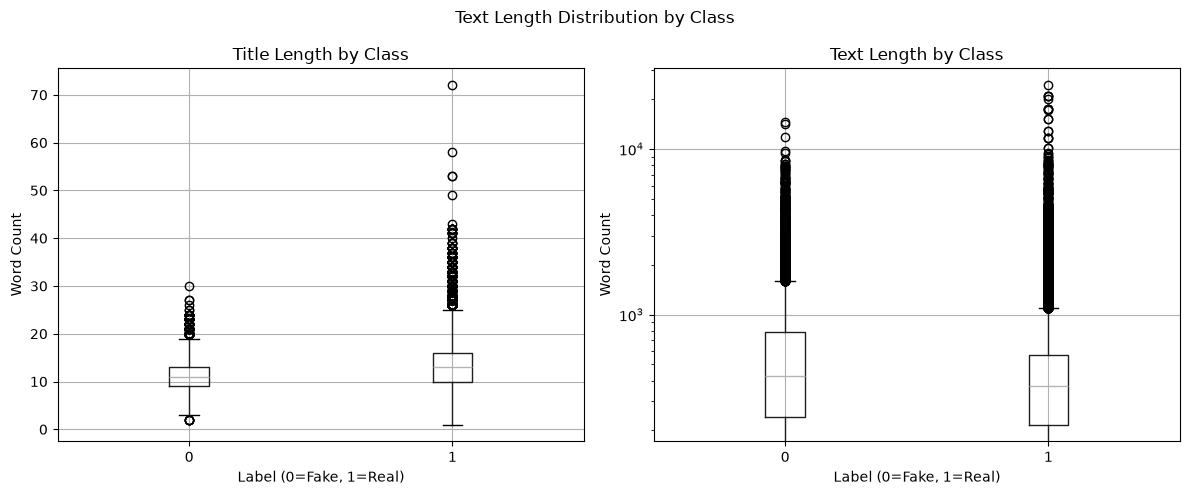

In [7]:
# text length by class - boxplot (log scale for text length due to extreme outliers)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df.boxplot(column='title_length', by='label', ax=axes[0])
axes[0].set_title('Title Length by Class')
axes[0].set_xlabel('Label (0=Fake, 1=Real)')
axes[0].set_ylabel('Word Count')

df.boxplot(column='text_length', by='label', ax=axes[1])
axes[1].set_title('Text Length by Class')
axes[1].set_xlabel('Label (0=Fake, 1=Real)')
axes[1].set_ylabel('Word Count')
axes[1].set_yscale('log')

plt.suptitle('Text Length Distribution by Class')
plt.tight_layout()
plt.show()

In [8]:
# check for missing values
print(df.isnull().sum())
print(df.isnull().sum() / len(df) * 100)

Unnamed: 0        0
title           558
text             39
label             0
title_length    558
text_length      39
dtype: int64
Unnamed: 0      0.000000
title           0.773560
text            0.054066
label           0.000000
title_length    0.773560
text_length     0.054066
dtype: float64


In [9]:
# duplicate records - based on article text, since title alone can miss or over-flag duplicates
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Duplicate text entries: {df.duplicated(subset=['text']).sum()}")

dup_texts = df[df.duplicated(subset=['text'], keep=False)]
label_consistency = dup_texts.groupby('text')['label'].nunique()
inconsistent = label_consistency[label_consistency > 1]

print(f"Number of unique duplicate text groups: {dup_texts['text'].nunique()}")
print(f"Duplicate groups with conflicting labels: {len(inconsistent)}")

Duplicate rows: 0
Duplicate text entries: 9415
Number of unique duplicate text groups: 7731
Duplicate groups with conflicting labels: 1


In [10]:
# Check for short/degenerate text entries (less than or equal to 3 words)
empty_text = (df['text'].dropna().str.strip() == '').sum()
print(f"Empty (whitespace-only) text entries: {empty_text}")

short_entries = df[df['text_length'] <= 3]
print(f"Entries with 3 words or fewer: {len(short_entries)}")
print(short_entries[['text', 'label']].head(10))

# class distribution of short entries
print(short_entries['label'].value_counts())


Empty (whitespace-only) text entries: 744
Entries with 3 words or fewer: 940
                                            text  label
7                                                     1
106                                                   1
185                                         Cool      1
325                                                   1
358                              Obamas blunder.      1
364                                                   1
421  https://www.youtube.com/watch?v=RRPSCqkAJgk      1
512                                                   1
514                                                   1
555                                                   1
label
1    937
0      3
Name: count, dtype: int64


## Text Data Preparation

### Data Cleaning

In [11]:
#Step 1: Drop Missing Values
print(f"Before dropping missing values: {len(df)} rows")
df_clean = df.dropna(subset=['title', 'text']).copy()
print(f"After dropping missing values: {len(df_clean)} rows")

# Step 2 - Remove short/degenerate entries (also resolves the conflicting-label group, which was blank text)
df_clean['text_length'] = df_clean['text'].apply(lambda x: len(str(x).split()))
print(f"Before removing short entries: {len(df_clean)} rows")
df_clean = df_clean[df_clean['text_length'] > 3]
print(f"After removing short entries: {len(df_clean)} rows")

# Step 3 - Drop duplicate text, keep first occurrence
print(f"Before deduplication: {len(df_clean)} rows")
df_clean = df_clean.drop_duplicates(subset=['text'], keep='first')
print(f"After deduplication: {len(df_clean)} rows")

# Final check
print(f"Final cleaned dataset size: {len(df_clean)} rows")
print(df_clean['label'].value_counts())
print(df_clean['label'].value_counts(normalize=True) * 100)

Before dropping missing values: 72134 rows
After dropping missing values: 71537 rows
Before removing short entries: 71537 rows
After removing short entries: 70639 rows
Before deduplication: 70639 rows
After deduplication: 62100 rows
Final cleaned dataset size: 62100 rows
label
0    34618
1    27482
Name: count, dtype: int64
label
0    55.745572
1    44.254428
Name: proportion, dtype: float64


### Text Normaliztion

In [12]:
import re

def normalize_text(text):
    text = str(text).lower()                           # lowercase
    text = re.sub(r'http\S+|www\S+', '', text)         # remove URLs
    text = re.sub(r'\d+', '', text)                    # remove numbers
    text = re.sub(r'[^\w\s]', '', text)                # remove punctuation
    text = re.sub(r'\s+', ' ', text).strip()           # normalize whitespace
    return text

df_clean['title_clean'] = df_clean['title'].apply(normalize_text)
df_clean['text_clean'] = df_clean['text'].apply(normalize_text)

# checking the first 3 rows of the cleaned and normalized dataset
df_clean[['title', 'title_clean', 'text', 'text_clean']].head(3)

,title,title_clean,text,text_clean
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,law enforcement on high alert following threat...,No comment is expected from Barack Obama Membe...,no comment is expected from barack obama membe...
2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,unbelievable obamas attorney general says most...,"Now, most of the demonstrators gathered last ...",now most of the demonstrators gathered last ni...
3,"Bobby Jindal, raised Hindu, uses story of Chri...",bobby jindal raised hindu uses story of christ...,A dozen politically active pastors came here f...,a dozen politically active pastors came here f...


### Tokenization

In [13]:

import nltk
nltk.download('punkt')
from nltk.tokenize import word_tokenize

df_clean['title_tokens'] = df_clean['title_clean'].apply(word_tokenize)
df_clean['text_tokens'] = df_clean['text_clean'].apply(word_tokenize)

df_clean[['title_clean', 'title_tokens']].head(3)

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\liewm\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


,title_clean,title_tokens
0,law enforcement on high alert following threat...,"[law, enforcement, on, high, alert, following,..."
2,unbelievable obamas attorney general says most...,"[unbelievable, obamas, attorney, general, says..."
3,bobby jindal raised hindu uses story of christ...,"[bobby, jindal, raised, hindu, uses, story, of..."


### Stopword Removal

In [14]:
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

def remove_stopwords(tokens):
    return [word for word in tokens if word not in stop_words]

df_clean['title_tokens_nostop'] = df_clean['title_tokens'].apply(remove_stopwords)
df_clean['text_tokens_nostop'] = df_clean['text_tokens'].apply(remove_stopwords)

df_clean[['title_tokens', 'title_tokens_nostop']].head(3)



,title_tokens,title_tokens_nostop
0,"[law, enforcement, on, high, alert, following,...","[law, enforcement, high, alert, following, thr..."
2,"[unbelievable, obamas, attorney, general, says...","[unbelievable, obamas, attorney, general, says..."
3,"[bobby, jindal, raised, hindu, uses, story, of...","[bobby, jindal, raised, hindu, uses, story, ch..."


In [15]:
# Check for empty text after stopword removal
empty_after_stopwords = df_clean[df_clean['text_tokens_nostop'].apply(len) == 0]
print(f"Rows with empty text after stopword removal: {len(empty_after_stopwords)}")

Rows with empty text after stopword removal: 1


In [16]:
# Remove rows with empty text after stopword removal
print(f"Before removing empty text after stopword removal: {len(df_clean)} rows")
df_clean = df_clean[df_clean['text_tokens_nostop'].apply(len) > 0]
print(f"After removing empty text after stopword removal: {len(df_clean)} rows")

Before removing empty text after stopword removal: 62100 rows
After removing empty text after stopword removal: 62099 rows


### Lemmatization

In [17]:
import nltk
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('averaged_perceptron_tagger_eng')

from nltk import pos_tag
from nltk.corpus import wordnet
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

def lemmatize_with_pos(tokens):
    tagged = pos_tag(tokens)
    return [lemmatizer.lemmatize(word, get_wordnet_pos(tag)) for word, tag in tagged]

df_clean['title_lemmatized'] = df_clean['title_tokens_nostop'].apply(lemmatize_with_pos)
df_clean['text_lemmatized'] = df_clean['text_tokens_nostop'].apply(lemmatize_with_pos)

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\liewm\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\liewm\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\liewm\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


### Vectorization

In [18]:
# tf-idf vectorization

# rejoin lemmatized tokens and combine title + text into one field
df_clean['text_final'] = df_clean['text_lemmatized'].apply(lambda tokens: ' '.join(tokens))
df_clean['title_final'] = df_clean['title_lemmatized'].apply(lambda tokens: ' '.join(tokens))
df_clean['combined_text'] = df_clean['title_final'] + ' ' + df_clean['text_final']

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)  # cap vocabulary size to keep it manageable
X = tfidf.fit_transform(df_clean['combined_text'])
y = df_clean['label']

print(X.shape) 

(62099, 5000)


### Train-test split

In [19]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Training set size: {X_train.shape[0]}")
print(f"Testing set size: {X_test.shape[0]}")
print(f"Training class distribution:\n{y_train.value_counts(normalize=True) * 100}")
print(f"Testing class distribution:\n{y_test.value_counts(normalize=True) * 100}")

Training set size: 49679
Testing set size: 12420
Training class distribution:
label
0    55.745889
1    44.254111
Name: proportion, dtype: float64
Testing class distribution:
label
0    55.748792
1    44.251208
Name: proportion, dtype: float64


## Modeling

#### Model 1:Logistic Regression

In [20]:
from sklearn.linear_model import LogisticRegression
import time

lr_model = LogisticRegression(max_iter=1000, random_state=42)

start = time.time()
lr_model.fit(X_train, y_train)
print(f"Training time: {time.time() - start:.2f} seconds")

lr_preds = lr_model.predict(X_test)

Training time: 0.66 seconds


### Model 2: Support Vector Machine (SVM)

In [21]:
from sklearn.svm import LinearSVC
import time

svm_model = LinearSVC(random_state=42, max_iter=2000)

start = time.time()
svm_model.fit(X_train, y_train)
print(f"Training time: {time.time() - start:.2f} seconds")

svm_preds = svm_model.predict(X_test)

Training time: 2.11 seconds


## Evaluation

### Model Performance Comparison

In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Evaluation Metrics
# Fake (label 0) is treated as the positive class, since detecting fake news is the primary goal.
def evaluate_model(y_true, y_pred, model_name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, pos_label=0)
    rec = recall_score(y_true, y_pred, pos_label=0)
    f1 = f1_score(y_true, y_pred, pos_label=0)
    roc_auc = roc_auc_score(y_true, y_pred)  

    print(f"{model_name}")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision (Fake as positive): {prec:.4f}")
    print(f"Recall (Fake as positive):    {rec:.4f}")
    print(f"F1-Score (Fake as positive):  {f1:.4f}")
    print(f"ROC-AUC:   {roc_auc:.4f}")
    print()

    return {'model': model_name, 'accuracy': acc, 'precision': prec, 'recall': rec, 'f1': f1, 'roc_auc': roc_auc}

lr_results = evaluate_model(y_test, lr_preds, "Logistic Regression")
svm_results = evaluate_model(y_test, svm_preds, "Support Vector Machine")

comparison_df = pd.DataFrame([lr_results, svm_results])
print(comparison_df)

Logistic Regression
Accuracy:  0.9507
Precision (Fake as positive): 0.9569
Recall (Fake as positive):    0.9547
F1-Score (Fake as positive):  0.9558
ROC-AUC:   0.9502

Support Vector Machine
Accuracy:  0.9522
Precision (Fake as positive): 0.9583
Recall (Fake as positive):    0.9558
F1-Score (Fake as positive):  0.9570
ROC-AUC:   0.9517

                    model  accuracy  precision    recall        f1   roc_auc
0     Logistic Regression  0.950725   0.956862  0.954650  0.955755  0.950215
1  Support Vector Machine  0.952174   0.958297  0.955806  0.957050  0.951702


### Model Interpretbility


In [23]:
import numpy as np

feature_names = tfidf.get_feature_names_out()

# Logistic Regression - positive coefficient = Real, negative = Fake
lr_coefficients = lr_model.coef_[0]
top_fake_idx_lr = np.argsort(lr_coefficients)[:10]
top_real_idx_lr = np.argsort(lr_coefficients)[-10:][::-1]

print("Logistic Regression - Top 10 words indicating FAKE:")
for i in top_fake_idx_lr:
    print(f"{feature_names[i]}: {lr_coefficients[i]:.4f}")

print("\nLogistic Regression - Top 10 words indicating REAL:")
for i in top_real_idx_lr:
    print(f"{feature_names[i]}: {lr_coefficients[i]:.4f}")

# SVM - same convention (classes_ = [0, 1] for both models)
svm_coefficients = svm_model.coef_[0]
top_fake_idx_svm = np.argsort(svm_coefficients)[:10]
top_real_idx_svm = np.argsort(svm_coefficients)[-10:][::-1]

print("\nSVM - Top 10 words indicating FAKE:")
for i in top_fake_idx_svm:
    print(f"{feature_names[i]}: {svm_coefficients[i]:.4f}")

print("\nSVM - Top 10 words indicating REAL:")
for i in top_real_idx_svm:
    print(f"{feature_names[i]}: {svm_coefficients[i]:.4f}")

Logistic Regression - Top 10 words indicating FAKE:
reuters: -25.2049
breitbart: -13.8966
say: -13.7456
twitter: -8.1387
york: -6.4635
thats: -6.1850
thursday: -6.0892
dont: -6.0192
com: -5.9708
friday: -5.8105

Logistic Regression - Top 10 words indicating REAL:
via: 15.2733
image: 12.3647
october: 8.6589
video: 7.4597
hillary: 7.2073
november: 6.8260
wire: 5.1673
obama: 4.4337
go: 4.1544
dc: 3.7986

SVM - Top 10 words indicating FAKE:
reuters: -18.9967
com: -7.8508
breitbart: -7.2557
pic: -5.3912
say: -4.8416
twitter: -4.3334
york: -4.1579
trumps: -3.7579
thursday: -3.4011
cruzs: -3.2909

SVM - Top 10 words indicating REAL:
via: 13.1176
image: 5.5968
october: 5.5058
november: 4.5183
wire: 3.5891
hillary: 3.3519
flickr: 3.1904
wow: 3.1902
video: 2.9577
yearold: 2.9521


### Confusion Matrix

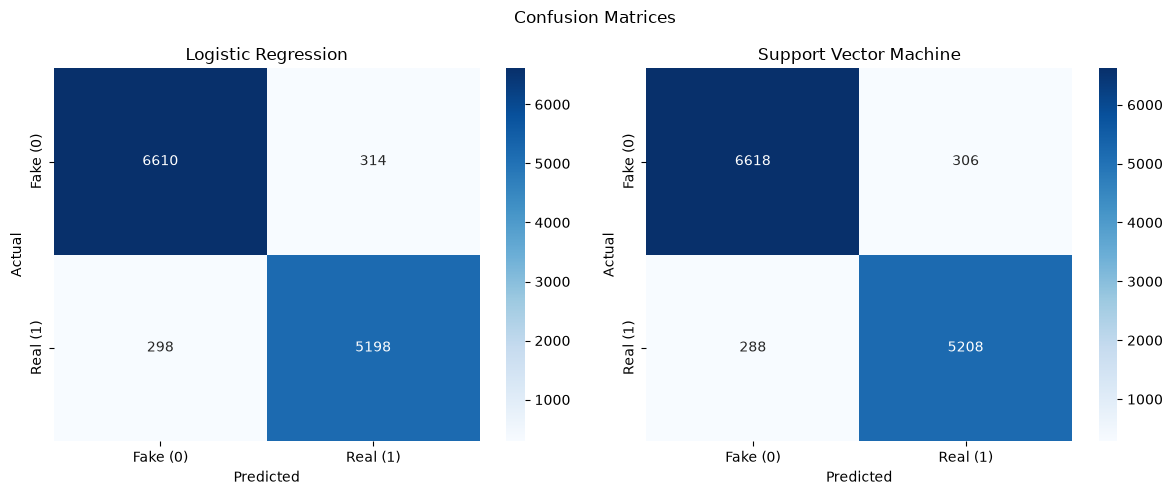

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_lr = confusion_matrix(y_test, lr_preds)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Fake (0)', 'Real (1)'], yticklabels=['Fake (0)', 'Real (1)'])
axes[0].set_title('Logistic Regression')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

cm_svm = confusion_matrix(y_test, svm_preds)
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Fake (0)', 'Real (1)'], yticklabels=['Fake (0)', 'Real (1)'])
axes[1].set_title('Support Vector Machine')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.suptitle('Confusion Matrices')
plt.tight_layout()
plt.show()